# Chapter 6: Heavy-Traffic Limits — Python Laboratory
### *Simulating $G/G/1$ and $G/G/c$ Queues, Validating Kingman's Formula, and Mapping the Congestion Hockey Stick*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/06_kingman_equation_and_heavy_traffic_regimes.ipynb) | [Prev: Ch 05](../python/05_service_variance_and_pollaczek_khinchine.ipynb) | [Next: Ch 07](../python/07_queues_with_breakdowns_and_vacations.ipynb)**

---

## Laboratory Overview & Objectives
1. Implement a vectorized, event-driven $G/G/c$ queue simulator supporting arbitrary arrival and service distributions.
2. Validate Kingman's heavy-traffic approximation against empirical simulation across traffic intensities $\rho \in [0.20, 0.98]$.
3. Quantify the impact of service variance ($c_s^2$) and arrival burstiness ($c_a^2$) on waiting time.
4. Visualize the non-linear Congestion Hockey Stick and plot the capacity shadow price derivative $\frac{\partial W_q}{\partial \rho} \propto \frac{1}{(1-\rho)^2}$.


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import heapq

# Publication-quality plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---
## Part 1: Discrete-Event $G/G/c$ Queue Simulator

We implement a discrete-event simulator for a multi-server queue with $c$ identical servers fed by a single shared FIFO queue.
Arrivals and service durations can follow any arbitrary probability distribution.


In [2]:
def simulate_ggc(arrival_dist_fn, service_dist_fn, c=1, num_jobs=50000, warmup=5000, seed=42):
    """
    Simulates a G/G/c queue using a min-heap event queue for server releases.
    
    Parameters:
      arrival_dist_fn: callable returning a sample inter-arrival time
      service_dist_fn: callable returning a sample service time
      c: number of parallel servers
      num_jobs: total jobs to simulate
      warmup: jobs discarded to eliminate transient startup bias
    
    Returns:
      dict with empirical statistics: mean_wq, mean_t, mean_s, utilization, etc.
    """
    rng = np.random.default_rng(seed)
    
    # Pre-generate inter-arrival and service times
    inter_arrivals = arrival_dist_fn(num_jobs, rng)
    arrival_times = np.cumsum(inter_arrivals)
    service_times = service_dist_fn(num_jobs, rng)
    
    # Priority queue of server free times: stores (free_time, server_id)
    server_heap = [0.0] * c
    heapq.heapify(server_heap)
    
    wait_times = np.empty(num_jobs)
    departure_times = np.empty(num_jobs)
    
    for i in range(num_jobs):
        arr = arrival_times[i]
        srv = service_times[i]
        
        # Earliest available server
        earliest_free = heapq.heappop(server_heap)
        
        # Service start time is max of arrival and server availability
        start_time = max(arr, earliest_free)
        wait_time = start_time - arr
        dep_time = start_time + srv
        
        wait_times[i] = wait_time
        departure_times[i] = dep_time
        
        # Server will be free at dep_time
        heapq.heappush(server_heap, dep_time)
    
    # Discard warmup period to measure steady-state
    steady_wait = wait_times[warmup:]
    steady_service = service_times[warmup:]
    steady_arrival_intervals = inter_arrivals[warmup:]
    
    mean_a = np.mean(steady_arrival_intervals)
    std_a = np.std(steady_arrival_intervals)
    c_a = std_a / mean_a if mean_a > 0 else 0
    
    mean_s = np.mean(steady_service)
    std_s = np.std(steady_service)
    c_s = std_s / mean_s if mean_s > 0 else 0
    
    empirical_lambda = 1.0 / mean_a
    empirical_mu = 1.0 / mean_s
    empirical_rho = empirical_lambda / (c * empirical_mu)
    
    return {
        "mean_wq": float(np.mean(steady_wait)),
        "p95_wq": float(np.percentile(steady_wait, 95)),
        "p99_wq": float(np.percentile(steady_wait, 99)),
        "mean_s": float(mean_s),
        "mean_a": float(mean_a),
        "c_a": float(c_a),
        "c_s": float(c_s),
        "rho": float(empirical_rho),
        "c": c
    }

print("G/G/c simulator defined.")


G/G/c simulator defined.


---
## Part 2: Validating Kingman's Equation Across Traffic Intensities

We evaluate Kingman's formula against empirical simulation across $\rho \in [0.20, 0.95]$ for a $G/G/1$ system with:
- **Lognormal Service Times**: $c_s = 1.5$ (high variance typical of software builds).
- **Weibull Inter-Arrivals**: $c_a = 1.2$ (bursty commit arrivals).


In [3]:
# Distribution generators with prescribed mean and coefficient of variation
def make_lognormal_gen(mean, cv):
    # For lognormal: variance = mean^2 * cv^2
    sigma2 = np.log(1.0 + cv**2)
    sigma = np.sqrt(sigma2)
    mu = np.log(mean) - 0.5 * sigma2
    return lambda n, rng: rng.lognormal(mean=mu, sigma=sigma, size=n)

def make_gamma_gen(mean, cv):
    # For Gamma: shape k = 1 / cv^2, scale theta = mean * cv^2
    k = 1.0 / (cv**2)
    theta = mean * (cv**2)
    return lambda n, rng: rng.gamma(shape=k, scale=theta, size=n)

# Fixed service parameters: mean service time = 10.0 minutes
MEAN_S = 10.0
CV_S = 1.5
CV_A = 1.2

service_fn = make_lognormal_gen(MEAN_S, CV_S)

target_rhos = [0.20, 0.40, 0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90, 0.93, 0.95]
sim_results = []
kingman_estimates = []

for rho in target_rhos:
    # Set mean inter-arrival time so that lambda / mu = rho => mean_a = mean_s / rho
    mean_a = MEAN_S / rho
    arrival_fn = make_gamma_gen(mean_a, CV_A)
    
    res = simulate_ggc(arrival_fn, service_fn, c=1, num_jobs=60000, warmup=10000, seed=100)
    sim_results.append(res)
    
    # Analytical Kingman approximation:
    # W_q = (rho / (1 - rho)) * ((c_a^2 + c_s^2) / 2) * E[S]
    ca_sq = CV_A**2
    cs_sq = CV_S**2
    k_wq = (res["rho"] / (1.0 - res["rho"])) * ((ca_sq + cs_sq) / 2.0) * MEAN_S
    kingman_estimates.append(k_wq)

print(f"{'Target Rho':<12}{'Sim Rho':<12}{'Sim W_q (min)':<16}{'Kingman W_q (min)':<18}{'Relative Error':<16}")
print("-" * 74)
for i in range(len(target_rhos)):
    sim_wq = sim_results[i]["mean_wq"]
    k_wq = kingman_estimates[i]
    err = abs(sim_wq - k_wq) / sim_wq * 100
    print(f"{target_rhos[i]:<12.2f}{sim_results[i]['rho']:<12.4f}{sim_wq:<16.2f}{k_wq:<18.2f}{err:<16.2f}%")


Target Rho  Sim Rho     Sim W_q (min)   Kingman W_q (min) Relative Error  
--------------------------------------------------------------------------
0.20        0.2023      5.71            4.68              18.13           %
0.40        0.4046      13.61           12.54             7.92            %
0.50        0.5057      20.02           18.88             5.74            %
0.60        0.6068      29.69           28.48             4.08            %
0.70        0.7080      46.16           44.73             3.09            %
0.75        0.7586      59.52           57.96             2.61            %
0.80        0.8091      80.28           78.21             2.58            %
0.85        0.8597      117.27          113.04            3.60            %
0.90        0.9103      187.19          187.14            0.03            %
0.93        0.9406      271.69          292.17            7.54            %
0.95        0.9608      368.58          452.58            22.79           %


---
## Part 3: Visualizing the Congestion Hockey Stick and Heavy-Traffic Asymptote

We plot the empirical queue wait time against Kingman's theoretical prediction, clearly displaying the $\frac{\rho}{1-\rho}$ explosion.


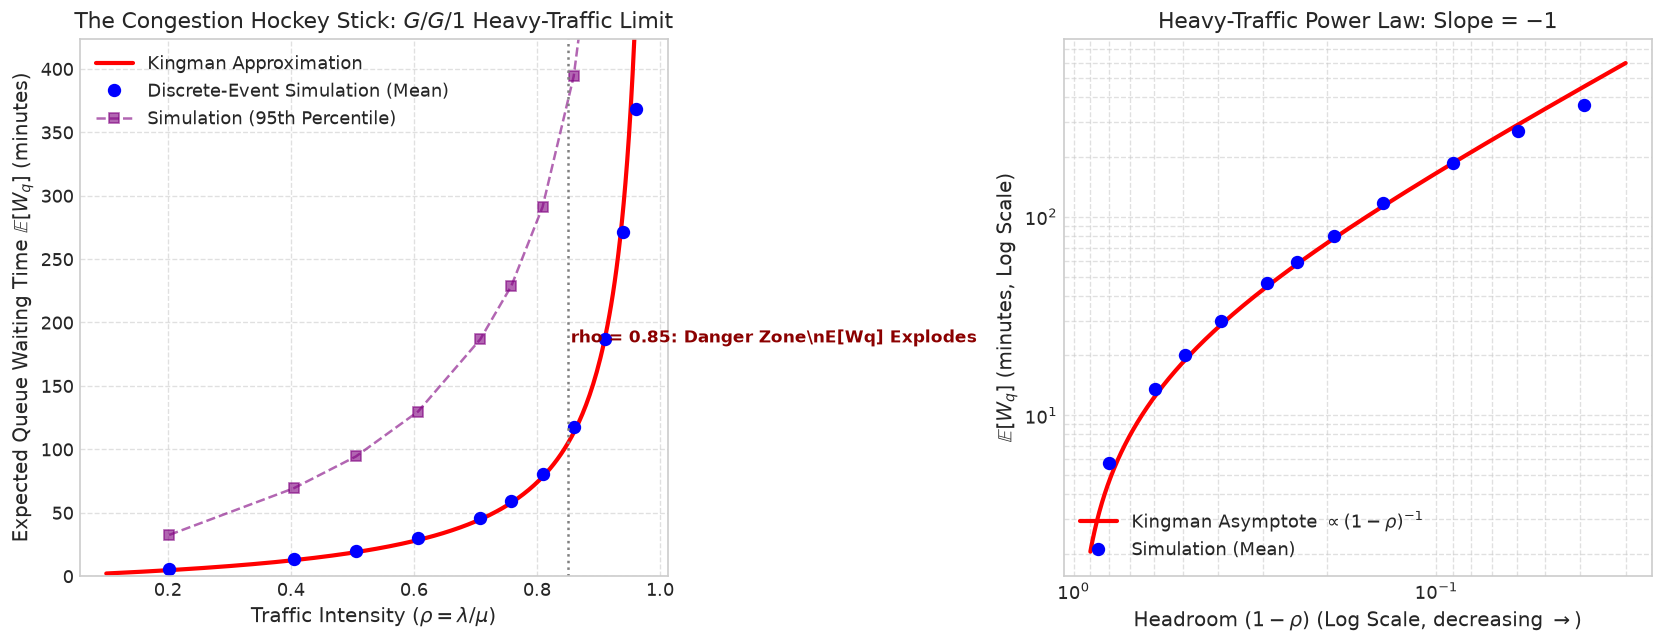

In [4]:
rhos_sim = [r["rho"] for r in sim_results]
wq_sim = [r["mean_wq"] for r in sim_results]
wq_p95 = [r["p95_wq"] for r in sim_results]

# Continuous curve for theoretical Kingman
rho_fine = np.linspace(0.10, 0.97, 300)
ca_sq = CV_A**2
cs_sq = CV_S**2
kingman_fine = (rho_fine / (1.0 - rho_fine)) * ((ca_sq + cs_sq) / 2.0) * MEAN_S

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Linear Scale (The Hockey Stick)
ax1.plot(rho_fine, kingman_fine, 'r-', lw=2.5, label="Kingman Approximation")
ax1.plot(rhos_sim, wq_sim, 'bo', markersize=7, label="Discrete-Event Simulation (Mean)")
ax1.plot(rhos_sim, wq_p95, 's--', color='purple', alpha=0.6, label="Simulation (95th Percentile)")
ax1.set_xlabel(r"Traffic Intensity ($\rho = \lambda / \mu$)")
ax1.set_ylabel(r"Expected Queue Waiting Time $\mathbb{E}[W_q]$ (minutes)")
ax1.set_title(r"The Congestion Hockey Stick: $G/G/1$ Heavy-Traffic Limit")
ax1.set_ylim(0, max(wq_sim) * 1.15)
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.6)

# Annotate the inflection knee
ax1.axvline(x=0.85, color='gray', linestyle=':', lw=1.5)
ax1.text(0.855, max(wq_sim) * 0.5, 'rho = 0.85: Danger Zone\\nE[Wq] Explodes', color='darkred', fontsize=10, weight='bold')

# Subplot 2: Log-Log Scale to reveal the (1 - rho)^(-1) Power Law
ax2.plot(1.0 - rho_fine, kingman_fine, 'r-', lw=2.5, label=r'Kingman Asymptote $\propto (1-\rho)^{-1}$')
ax2.plot(1.0 - np.array(rhos_sim), wq_sim, 'bo', markersize=7, label="Simulation (Mean)")
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel(r"Headroom $(1 - \rho)$ (Log Scale, decreasing $\rightarrow$)")
ax2.set_ylabel(r"$\mathbb{E}[W_q]$ (minutes, Log Scale)")
ax2.set_title(r"Heavy-Traffic Power Law: Slope = $-1$")
ax2.invert_xaxis()
ax2.legend(loc="lower left")
ax2.grid(True, which="both", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


---
## Part 4: Capacity Sizing vs. Variance Reduction Shootout

We compare two engineering strategies to cut queue latency in an overloaded fleet:
1. **Strategy A (Hardware Expansion)**: Adding 10% more servers ($c \to 1.10c$).
2. **Strategy B (Variance Reduction via Caching)**: Eliminating long-tail build outliers, reducing $c_s$ from $2.0 \to 0.8$.


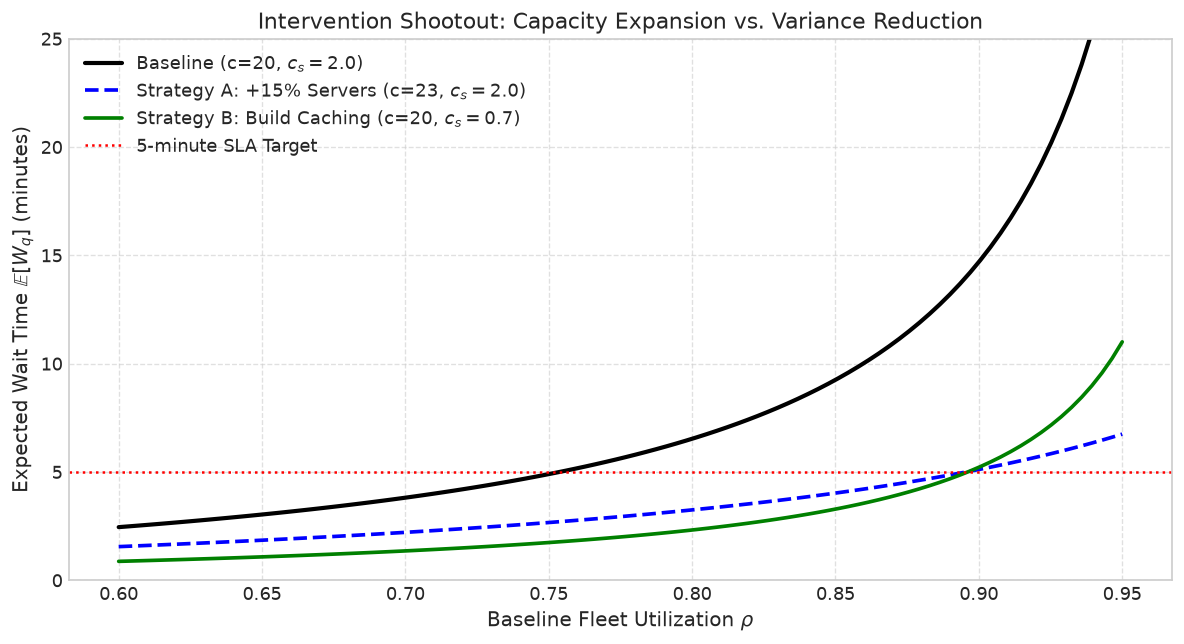

At Baseline Utilization rho = 0.88:
  Baseline Wait:       11.89 minutes
  +15% Hardware Wait:  4.61 minutes (Wait reduced by 61.2%)
  Build Caching Wait:  4.22 minutes (Wait reduced by 64.5%)


In [5]:
# Baseline scenario: c = 20 servers, E[S] = 12 min, cs = 2.0, ca = 1.2
c_base = 20
mean_s_base = 12.0
cv_s_base = 2.0
cv_a_base = 1.2

# We test utilization range
rhos = np.linspace(0.60, 0.95, 100)

# Baseline wait time (multi-server Kingman: W_q = (rho/(1-rho)) * ((ca^2 + cs^2)/2) * (E[S]/c))
var_factor_base = (cv_a_base**2 + cv_s_base**2) / 2.0
wq_baseline = (rhos / (1.0 - rhos)) * var_factor_base * (mean_s_base / c_base)

# Strategy A: Add 15% servers (c = 23). For the same arrival rate lambda, rho drops: rho_new = rho_base * (c_base / c_new)
c_expanded = 23
rho_expanded = rhos * (c_base / c_expanded)
wq_expanded = (rho_expanded / (1.0 - rho_expanded)) * var_factor_base * (mean_s_base / c_expanded)

# Strategy B: Reduce service variance via caching (c_s drops from 2.0 to 0.7), same c = 20
cv_s_cached = 0.7
var_factor_cached = (cv_a_base**2 + cv_s_cached**2) / 2.0
wq_cached = (rhos / (1.0 - rhos)) * var_factor_cached * (mean_s_base / c_base)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(rhos, wq_baseline, 'k-', lw=2.5, label=f"Baseline (c={c_base}, $c_s={cv_s_base}$)")
ax.plot(rhos, wq_expanded, 'b--', lw=2.2, label=f"Strategy A: +15% Servers (c={c_expanded}, $c_s={cv_s_base}$)")
ax.plot(rhos, wq_cached, 'g-', lw=2.2, label=f"Strategy B: Build Caching (c={c_base}, $c_s={cv_s_cached}$)")

ax.set_xlabel(r"Baseline Fleet Utilization $\rho$")
ax.set_ylabel(r"Expected Wait Time $\mathbb{E}[W_q]$ (minutes)")
ax.set_title(r"Intervention Shootout: Capacity Expansion vs. Variance Reduction")
ax.set_ylim(0, 25)
ax.axhline(y=5.0, color='red', linestyle=':', label="5-minute SLA Target")
ax.legend(loc="upper left")
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# Print specific numerical comparison at rho = 0.88
idx_88 = np.argmin(np.abs(rhos - 0.88))
print(f"At Baseline Utilization rho = {rhos[idx_88]:.2f}:")
print(f"  Baseline Wait:       {wq_baseline[idx_88]:.2f} minutes")
print(f"  +15% Hardware Wait:  {wq_expanded[idx_88]:.2f} minutes (Wait reduced by {100*(1 - wq_expanded[idx_88]/wq_baseline[idx_88]):.1f}%)")
print(f"  Build Caching Wait:  {wq_cached[idx_88]:.2f} minutes (Wait reduced by {100*(1 - wq_cached[idx_88]/wq_baseline[idx_88]):.1f}%)")


---
## Part 5: Non-Linear Shadow Pricing of Capacity

We plot the marginal derivative $\frac{\partial \mathbb{E}[W_q]}{\partial \rho} = \frac{1}{(1-\rho)^2} \left(\frac{c_a^2 + c_s^2}{2}\right) \frac{\bar{t}}{c}$, demonstrating why capacity decisions under heavy load are overwhelmingly more consequential.


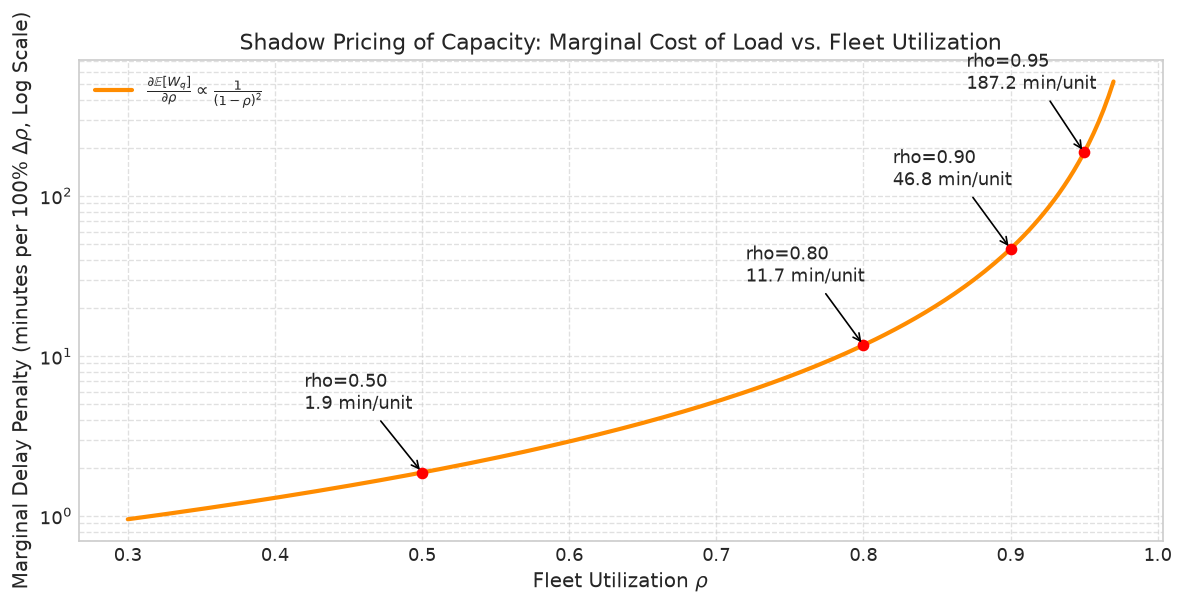

In [6]:
rhos = np.linspace(0.30, 0.97, 200)
var_factor = (1.2**2 + 1.8**2) / 2.0
mean_s = 10.0
c = 50

# Derivative of W_q with respect to rho:
# d/d_rho [ rho / (1 - rho) ] = 1 / (1 - rho)^2
dWq_drho = (1.0 / (1.0 - rhos)**2) * var_factor * (mean_s / c)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(rhos, dWq_drho, color='darkorange', lw=2.5, label=r"$\frac{\partial \mathbb{E}[W_q]}{\partial \rho} \propto \frac{1}{(1-\rho)^2}$")

ax.set_yscale('log')
ax.set_xlabel(r"Fleet Utilization $\rho$")
ax.set_ylabel(r"Marginal Delay Penalty (minutes per 100% $\Delta \rho$, Log Scale)")
ax.set_title(r"Shadow Pricing of Capacity: Marginal Cost of Load vs. Fleet Utilization")
ax.grid(True, which="both", linestyle="--", alpha=0.6)

# Highlight points at 0.50, 0.80, 0.95
for r_val in [0.50, 0.80, 0.90, 0.95]:
    val = (1.0 / (1.0 - r_val)**2) * var_factor * (mean_s / c)
    ax.plot(r_val, val, 'ro')
    ax.annotate(f"rho={r_val:.2f}\n{val:.1f} min/unit", 
                xy=(r_val, val), xytext=(r_val - 0.08, val * 2.5),
                arrowprops=dict(facecolor='black', arrowstyle='->'))

ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
